In [ ]:
# If needed, uncomment and run once:
# %pip install pandas numpy matplotlib seaborn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 30)
BASE = Path.cwd()
if not (BASE / "ai_job_dataset.csv").exists():
    BASE = Path("/mnt/data")  

raw = {
    "Dataset A": pd.read_csv(BASE / "ai_job_dataset.csv"),
    "Dataset B": pd.read_csv(BASE / "ai_job_dataset1.csv"),
}
for name, frame in raw.items():
    print(f"{name}: {frame.shape[0]:,} rows × {frame.shape[1]} columns")
    display(frame.head(3))

Dataset A: 15,000 rows × 19 columns


,job_id,job_title,salary_usd,salary_currency,experience_level,employment_type,company_location,company_size,employee_residence,remote_ratio,required_skills,education_required,years_experience,industry,posting_date,application_deadline,job_description_length,benefits_score,company_name
0,AI00001,AI Research Scientist,90376,USD,SE,CT,China,M,China,50,"Tableau, PyTorch, Kubernetes, Linux, NLP",Bachelor,9,Automotive,2024-10-18,2024-11-07,1076,5.9,Smart Analytics
1,AI00002,AI Software Engineer,61895,USD,EN,CT,Canada,M,Ireland,100,"Deep Learning, AWS, Mathematics, Python, Docker",Master,1,Media,2024-11-20,2025-01-11,1268,5.2,TechCorp Inc
2,AI00003,AI Specialist,152626,USD,MI,FL,Switzerland,L,South Korea,0,"Kubernetes, Deep Learning, Java, Hadoop, NLP",Associate,2,Education,2025-03-18,2025-04-07,1974,9.4,Autonomous Tech


Dataset B: 15,000 rows × 20 columns


,job_id,job_title,salary_usd,salary_currency,salary_local,experience_level,employment_type,company_location,company_size,employee_residence,remote_ratio,required_skills,education_required,years_experience,industry,posting_date,application_deadline,job_description_length,benefits_score,company_name
0,AI00001,Data Scientist,219728,USD,219728,EX,PT,Sweden,M,Sweden,0,"Python, Computer Vision, R, Docker",Associate,13,Transportation,2024-09-23,2024-10-31,1132,6.6,TechCorp Inc
1,AI00002,Head of AI,230237,JPY,25326070,EX,PT,Japan,L,Japan,50,"Kubernetes, MLOps, Tableau, Python",Bachelor,10,Transportation,2024-07-26,2024-09-12,2299,8.5,Cloud AI Solutions
2,AI00003,Data Engineer,128890,EUR,109557,EX,CT,Germany,S,Germany,100,"Spark, Scala, Hadoop, PyTorch, GCP",Bachelor,12,Automotive,2025-01-19,2025-03-28,1329,5.5,Quantum Computing Inc


In [2]:
for name, df in raw.items():
    print("\n", "="*65, "\n", name)
    print("Shape:", df.shape, "| Exact duplicates:", df.duplicated().sum())
    print("Columns:", df.columns.tolist())
    print("Data types:")
    display(df.dtypes.rename("dtype").to_frame().T)
    print("Numerical summary:")
    display(df.describe().round(2))
    print("Categorical summary:")
    display(df.describe(include="object").T[["count", "unique", "top", "freq"]])


 Dataset A
Shape: (15000, 19) | Exact duplicates: 0
Columns: ['job_id', 'job_title', 'salary_usd', 'salary_currency', 'experience_level', 'employment_type', 'company_location', 'company_size', 'employee_residence', 'remote_ratio', 'required_skills', 'education_required', 'years_experience', 'industry', 'posting_date', 'application_deadline', 'job_description_length', 'benefits_score', 'company_name']
Data types:


,job_id,job_title,salary_usd,salary_currency,experience_level,employment_type,company_location,company_size,employee_residence,remote_ratio,required_skills,education_required,years_experience,industry,posting_date,application_deadline,job_description_length,benefits_score,company_name
dtype,str,str,int64,str,str,str,str,str,str,int64,str,str,int64,str,str,str,int64,float64,str


Numerical summary:


,salary_usd,remote_ratio,years_experience,job_description_length,benefits_score
count,15000.00,15000.00,15000.00,15000.00,15000.00
mean,115348.97,49.48,6.25,1503.31,7.50
std,60260.94,40.81,5.55,576.13,1.45
min,32519.00,0.00,0.00,500.00,5.00
25%,70179.75,0.00,2.00,1003.75,6.20
50%,99705.00,50.00,5.00,1512.00,7.50
75%,146408.50,100.00,10.00,2000.00,8.80
max,399095.00,100.00,19.00,2499.00,10.00


Categorical summary:


C:\Users\iAT\AppData\Local\Temp\ipykernel_32008\3970889642.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include="object").T[["count", "unique", "top", "freq"]])


... (4 outputs left out)

,salary_usd,salary_local,remote_ratio,years_experience,job_description_length,benefits_score
count,15000.00,15000.00,15000.00,15000.00,15000.00,15000.00
mean,121991.94,829236.58,50.20,6.37,1500.85,7.50
std,63968.36,3425324.58,40.84,5.60,574.72,1.44
min,16621.00,16621.00,0.00,0.00,500.00,5.00
25%,74978.50,73830.75,0.00,2.00,998.75,6.30
50%,107261.50,109035.50,50.00,5.00,1512.00,7.50
75%,155752.25,167327.75,100.00,10.00,1994.00,8.80
max,410273.00,33685410.00,100.00,19.00,2499.00,10.00


Categorical summary:


C:\Users\iAT\AppData\Local\Temp\ipykernel_32008\3970889642.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include="object").T[["count", "unique", "top", "freq"]])


,count,unique,top,freq
job_id,15000,15000,AI00001,1
job_title,15000,20,Machine Learning Engineer,824
salary_currency,15000,8,USD,7453
experience_level,15000,4,EX,3843
employment_type,15000,4,CT,3841
company_location,15000,20,Switzerland,819
company_size,15000,3,L,5087
employee_residence,15000,50,Switzerland,669
required_skills,15000,13651,"Python, TensorFlow, Tableau",9
education_required,15000,4,Bachelor,3863


In [3]:
for name, df in raw.items():
    print(f"\n{name} — categorical distributions")
    for col in ["experience_level", "employment_type", "company_size", "remote_ratio", "salary_currency"]:
        print(f"{col}: {df[col].value_counts(dropna=False).to_dict()}")


Dataset A — categorical distributions
experience_level: {'MI': 3781, 'EX': 3760, 'SE': 3741, 'EN': 3718}
employment_type: {'FT': 3812, 'FL': 3758, 'CT': 3721, 'PT': 3709}
company_size: {'S': 5007, 'L': 4998, 'M': 4995}
remote_ratio: {0: 5075, 50: 5005, 100: 4920}
salary_currency: {'USD': 11957, 'EUR': 2314, 'GBP': 729}

Dataset B — categorical distributions
experience_level: {'EX': 3843, 'MI': 3764, 'SE': 3741, 'EN': 3652}
employment_type: {'CT': 3841, 'PT': 3757, 'FL': 3705, 'FT': 3697}
company_size: {'L': 5087, 'S': 4975, 'M': 4938}
remote_ratio: {100: 5034, 50: 4991, 0: 4975}
salary_currency: {'USD': 7453, 'EUR': 2942, 'CHF': 819, 'CAD': 781, 'GBP': 780, 'SGD': 762, 'JPY': 742, 'AUD': 721}


In [4]:
a, b = raw["Dataset A"], raw["Dataset B"]
common_ids = set(a.job_id).intersection(b.job_id)
print("Unique IDs in A:", a.job_id.nunique())
print("Unique IDs in B:", b.job_id.nunique())
print("Shared IDs:", len(common_ids))
comparison = a.merge(b, on="job_id", suffixes=("_A", "_B"), validate="one_to_one")
for col in ["job_title", "salary_usd", "posting_date", "company_name", "industry"]:
    matches = comparison[f"{col}_A"].eq(comparison[f"{col}_B"]).sum()
    print(f"Matching {col} for same ID: {matches:,}/{len(comparison):,}")
all_three = (comparison.job_title_A.eq(comparison.job_title_B) &
             comparison.salary_usd_A.eq(comparison.salary_usd_B) &
             comparison.posting_date_A.eq(comparison.posting_date_B))
print("Matching title + salary + date together:", int(all_three.sum()))
display(comparison[["job_id", "job_title_A", "job_title_B", "salary_usd_A", "salary_usd_B"]].head())
print("DECISION: analyze as separate samples; do not sum unique job counts.")

Unique IDs in A: 15000
Unique IDs in B: 15000
Shared IDs: 15000
Matching job_title for same ID: 720/15,000
Matching salary_usd for same ID: 0/15,000
Matching posting_date for same ID: 29/15,000
Matching company_name for same ID: 923/15,000
Matching industry for same ID: 981/15,000
Matching title + salary + date together: 0


,job_id,job_title_A,job_title_B,salary_usd_A,salary_usd_B
0,AI00001,AI Research Scientist,Data Scientist,90376,219728
1,AI00002,AI Software Engineer,Head of AI,61895,230237
2,AI00003,AI Specialist,Data Engineer,152626,128890
3,AI00004,NLP Engineer,Computer Vision Engineer,80215,96349
4,AI00005,AI Consultant,Robotics Engineer,54624,63065


DECISION: analyze as separate samples; do not sum unique job counts.


In [5]:
quality = []
clean = {}
for name, original in raw.items():
    df = original.copy()
    for c in ["posting_date", "application_deadline"]:
        df[c] = pd.to_datetime(df[c], errors="coerce")
    for c in ["salary_usd", "years_experience", "remote_ratio", "benefits_score"]:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    before = len(df)
    exact_dupes = int(df.duplicated().sum())
    duplicate_ids = int(df.job_id.duplicated().sum())
    invalid = (df.salary_usd.isna() | df.salary_usd.le(0) |
               df.posting_date.isna() | df.application_deadline.isna() |
               df.application_deadline.lt(df.posting_date) |
               df.years_experience.lt(0) |
               ~df.remote_ratio.isin([0, 50, 100]))
    invalid_count = int(invalid.sum())
    missing_before = int(df.isna().sum().sum())
    df = df.loc[~invalid].drop_duplicates().copy()
    df["posting_month"] = df.posting_date.dt.to_period("M").astype(str)
    df["remote_type"] = df.remote_ratio.map({0: "Onsite", 50: "Hybrid", 100: "Remote"})
    df["experience_label"] = df.experience_level.map({"EN": "Entry", "MI": "Mid", "SE": "Senior", "EX": "Executive"}).fillna("Other")
    df["salary_band"] = pd.cut(df.salary_usd, [0, 60000, 100000, 150000, 200000, np.inf],
                               labels=["<60k", "60–100k", "100–150k", "150–200k", "200k+"])
    df["application_window_days"] = (df.application_deadline - df.posting_date).dt.days
    clean[name] = df
    quality.append({"Dataset": name, "Original rows": before, "Missing cells": missing_before,
                    "Exact duplicates": exact_dupes, "Duplicate IDs": duplicate_ids,
                    "Invalid rows": invalid_count, "Retained rows": len(df)})
quality_table = pd.DataFrame(quality).set_index("Dataset")
display(quality_table)
print("Cleaning principle: no imputation without actual missing data; no automatic outlier deletion.")

,Original rows,Missing cells,Exact duplicates,Duplicate IDs,Invalid rows,Retained rows
Dataset,,,,,,
Dataset A,15000,0,0,0,0,15000
Dataset B,15000,0,0,0,0,15000


Cleaning principle: no imputation without actual missing data; no automatic outlier deletion.


In [6]:
for name, df in clean.items():
    q1, q3 = df.salary_usd.quantile([.25, .75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    df["salary_iqr_outlier"] = ~df.salary_usd.between(lower, upper)
    print(f"{name}: IQR={iqr:,.0f}, upper fence=${upper:,.0f}, flagged={df.salary_iqr_outlier.sum():,} ({df.salary_iqr_outlier.mean():.1%})")
print("Flagged records stay in analysis; medians reduce sensitivity to extreme values.")

Dataset A: IQR=76,229, upper fence=$260,752, flagged=483 (3.2%)
Dataset B: IQR=80,774, upper fence=$276,913, flagged=409 (2.7%)
Flagged records stay in analysis; medians reduce sensitivity to extreme values.


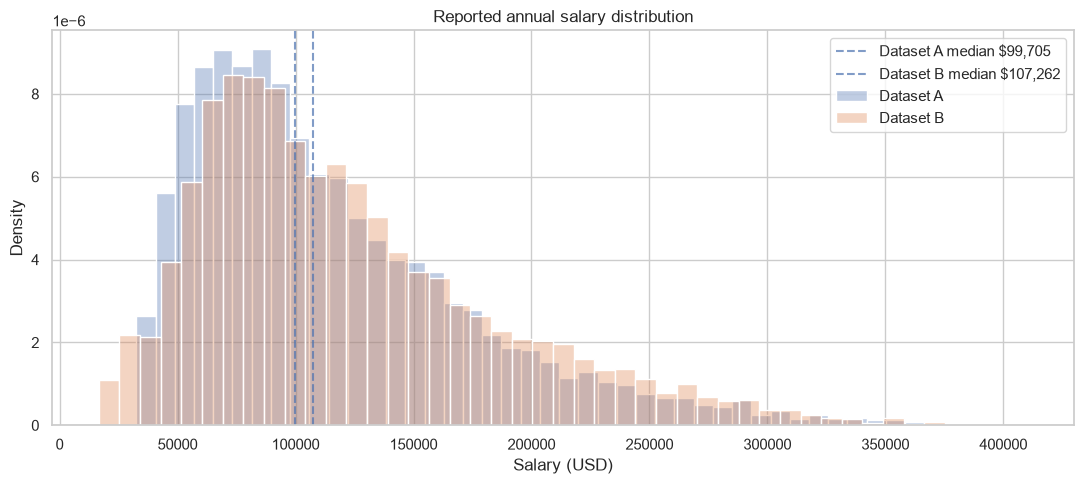

In [7]:
fig, ax = plt.subplots(figsize=(11, 5))
for i, (name, df) in enumerate(clean.items()):
    sns.histplot(df.salary_usd, bins=45, alpha=.35, stat="density", label=name, color=sns.color_palette()[i], ax=ax)
    ax.axvline(df.salary_usd.median(), linestyle="--", alpha=.7, label=f"{name} median ${df.salary_usd.median():,.0f}")
ax.set(title="Reported annual salary distribution", xlabel="Salary (USD)", ylabel="Density")
ax.legend(); plt.tight_layout(); plt.show()

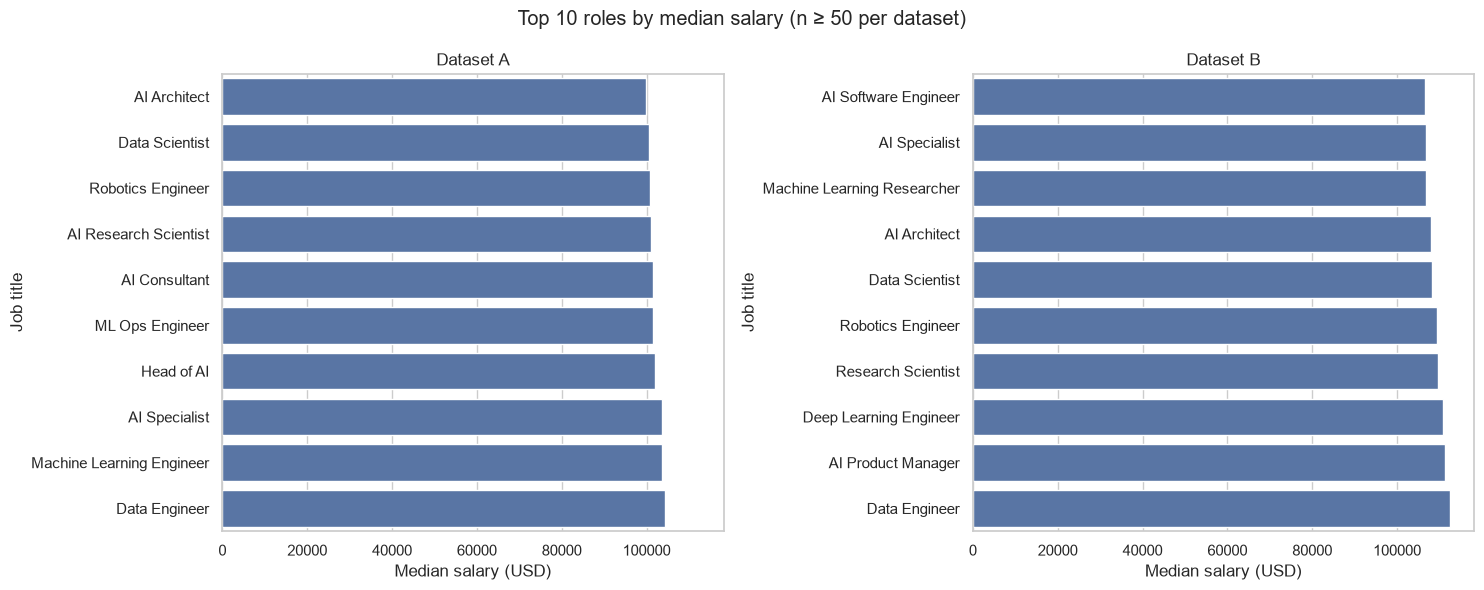

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True)
for ax, (name, df) in zip(axes, clean.items()):
    by_role = df.groupby("job_title").salary_usd.agg(["median", "size"])
    top = by_role.loc[by_role["size"] >= 50].nlargest(10, "median").sort_values("median")
    sns.barplot(x=top["median"], y=top.index, ax=ax, color=sns.color_palette()[0])
    ax.set(title=name, xlabel="Median salary (USD)", ylabel="Job title")
plt.suptitle("Top 10 roles by median salary (n ≥ 50 per dataset)"); plt.tight_layout(); plt.show()

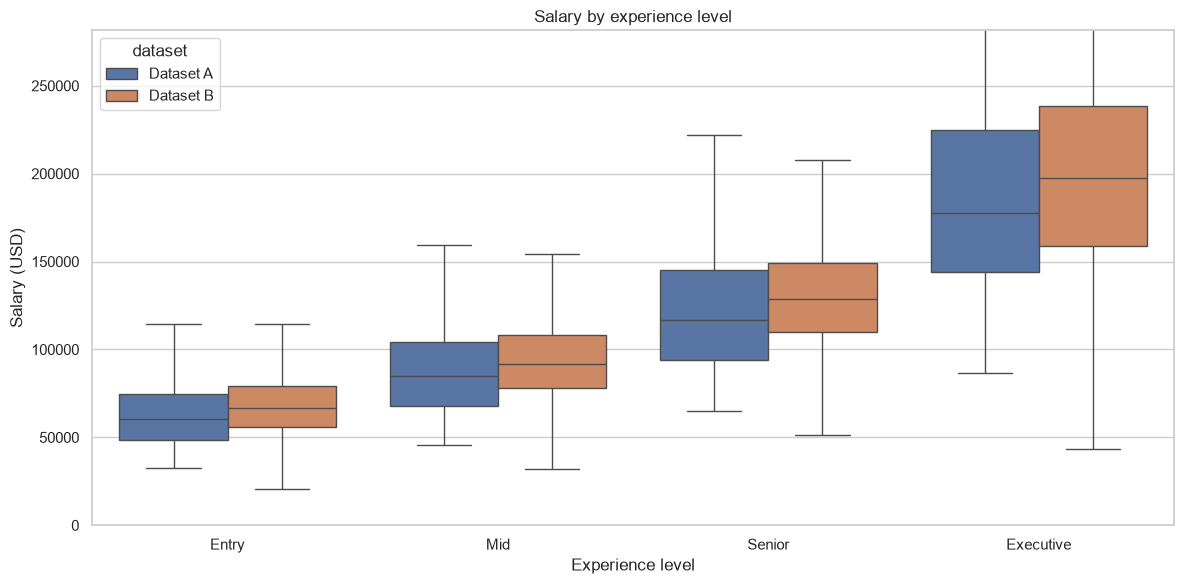

dataset,Dataset A,Dataset B
experience_label,,
Entry,60374.0,66462.0
Mid,84641.0,91597.0
Senior,116907.0,128543.0
Executive,177512.0,197354.0


In [9]:
plot_df = pd.concat([df.assign(dataset=name) for name, df in clean.items()], ignore_index=True)
order = ["Entry", "Mid", "Senior", "Executive"]
fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(data=plot_df, x="experience_label", y="salary_usd", hue="dataset", order=order,
            showfliers=False, ax=ax)
ax.set_ylim(0, plot_df.salary_usd.quantile(.95)*1.15)
ax.set(title="Salary by experience level", xlabel="Experience level", ylabel="Salary (USD)")
plt.tight_layout(); plt.show()
display(plot_df.pivot_table(index="experience_label", columns="dataset", values="salary_usd", aggfunc="median").reindex(order).round(0))

median      mean  size
dataset   remote_type                          
Dataset A Hybrid        99295.0  115777.0  5005
          Onsite        98817.0  114140.0  5075
          Remote       100614.0  116161.0  4920
Dataset B Hybrid       108528.0  122261.0  4991
          Onsite       106506.0  121582.0  4975
          Remote       107070.0  122131.0  5034

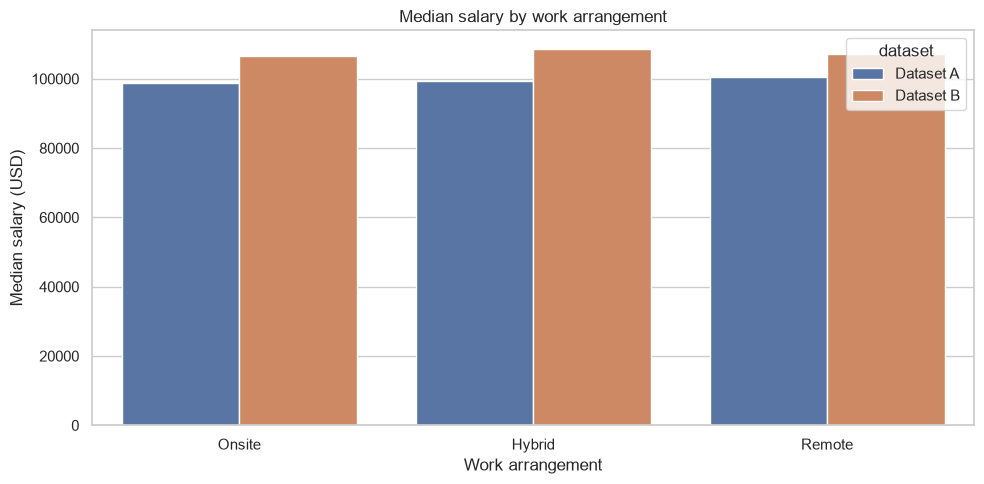

In [10]:
remote_stats = plot_df.groupby(["dataset", "remote_type"]).salary_usd.agg(["median", "mean", "size"]).round(0)
display(remote_stats)
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=plot_df, x="remote_type", y="salary_usd", hue="dataset",
            estimator=np.median, errorbar=None, order=["Onsite", "Hybrid", "Remote"], ax=ax)
ax.set(title="Median salary by work arrangement", xlabel="Work arrangement", ylabel="Median salary (USD)")
plt.tight_layout(); plt.show()

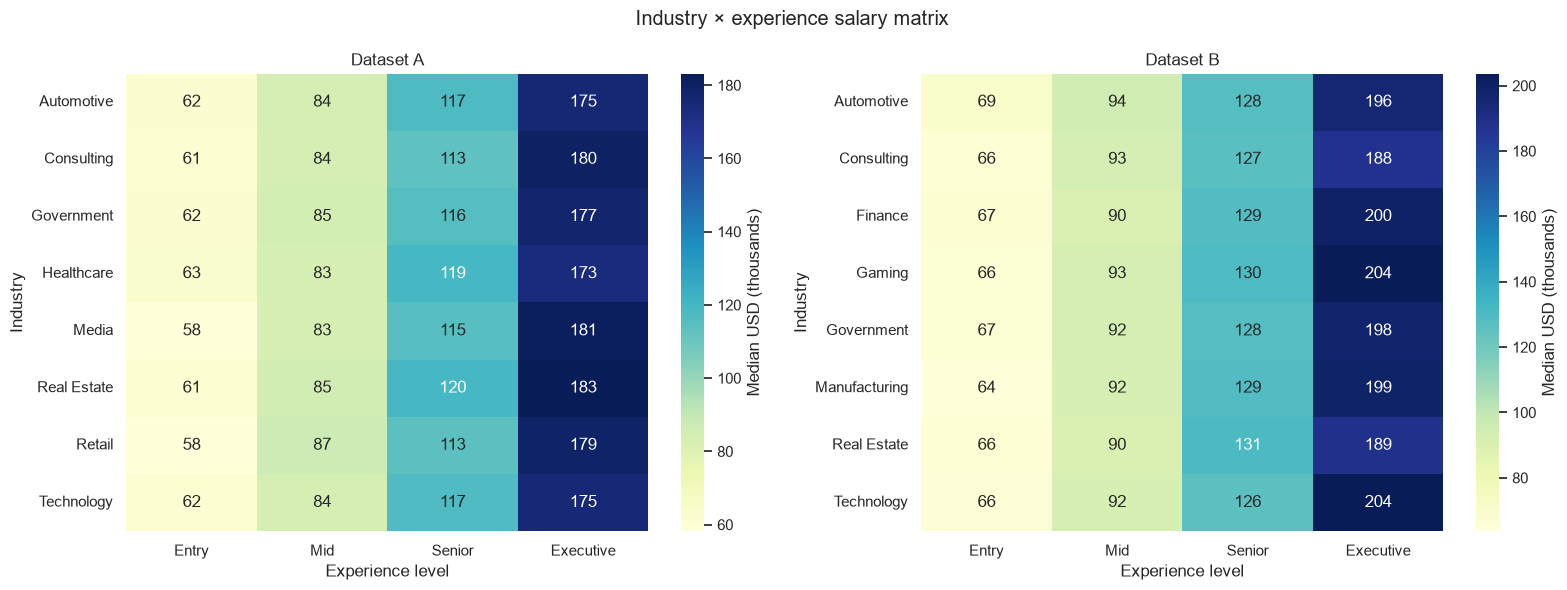

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, (name, df) in zip(axes, clean.items()):
    industries = df.industry.value_counts().head(8).index
    sub = df[df.industry.isin(industries)]
    table = sub.pivot_table(index="industry", columns="experience_label", values="salary_usd", aggfunc="median")
    table = table.reindex(columns=order)
    sns.heatmap(table/1000, annot=True, fmt=".0f", cmap="YlGnBu", ax=ax, cbar_kws={"label": "Median USD (thousands)"})
    ax.set(title=name, xlabel="Experience level", ylabel="Industry")
plt.suptitle("Industry × experience salary matrix"); plt.tight_layout(); plt.show()

Dataset A: 24 unique skill labels


,Mentions
required_skills,
Python,4450
SQL,3407
TensorFlow,3022
Kubernetes,3009
Scala,2794
PyTorch,2777
Linux,2705
Git,2631
Java,2578


Dataset B: 24 unique skill labels


,Mentions
required_skills,
Python,4499
SQL,3511
TensorFlow,3096
Kubernetes,3078
PyTorch,2831
Scala,2748
Linux,2642
Java,2531
Git,2491


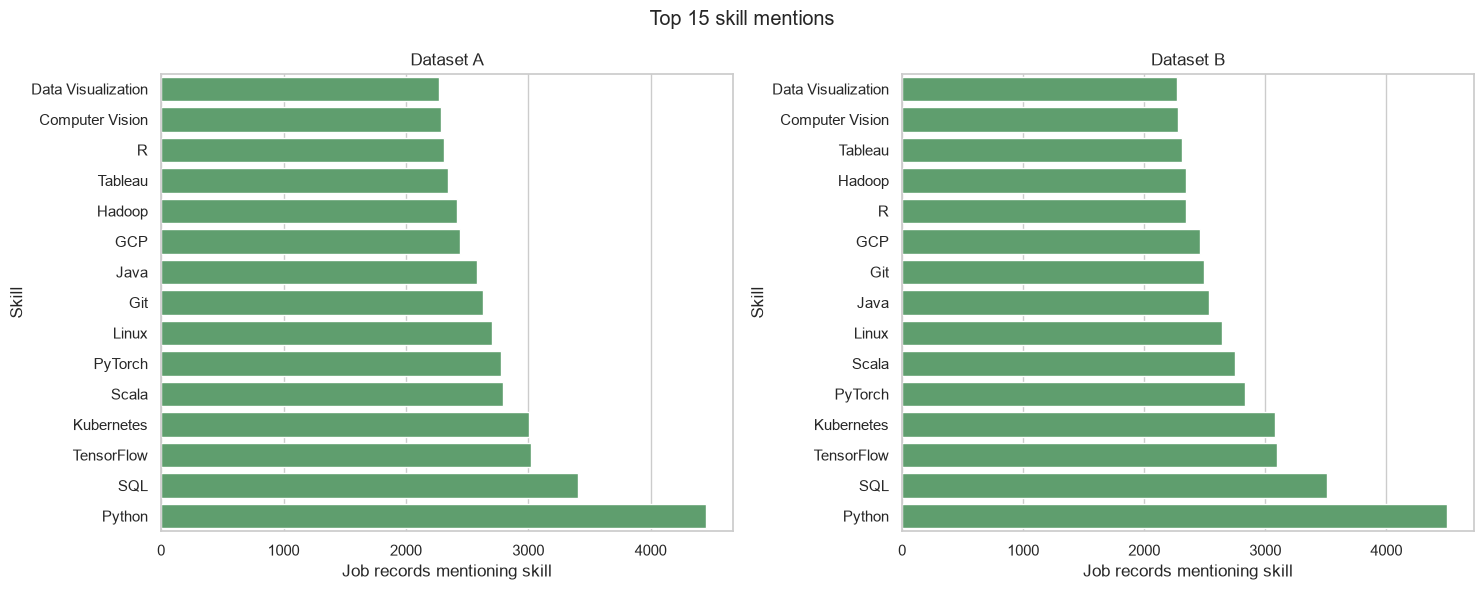

In [12]:
skill_counts = {}
for name, df in clean.items():
    expanded = df["required_skills"].fillna("").str.split(",").explode().str.strip()
    expanded = expanded[expanded.ne("")]
    skill_counts[name] = expanded.value_counts()
    print(f"{name}: {expanded.nunique()} unique skill labels")
    display(skill_counts[name].head(15).rename("Mentions").to_frame())
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (name, counts) in zip(axes, skill_counts.items()):
    top = counts.head(15).sort_values()
    sns.barplot(x=top.values, y=top.index, ax=ax, color=sns.color_palette()[2])
    ax.set(title=name, xlabel="Job records mentioning skill", ylabel="Skill")
plt.suptitle("Top 15 skill mentions"); plt.tight_layout(); plt.show()

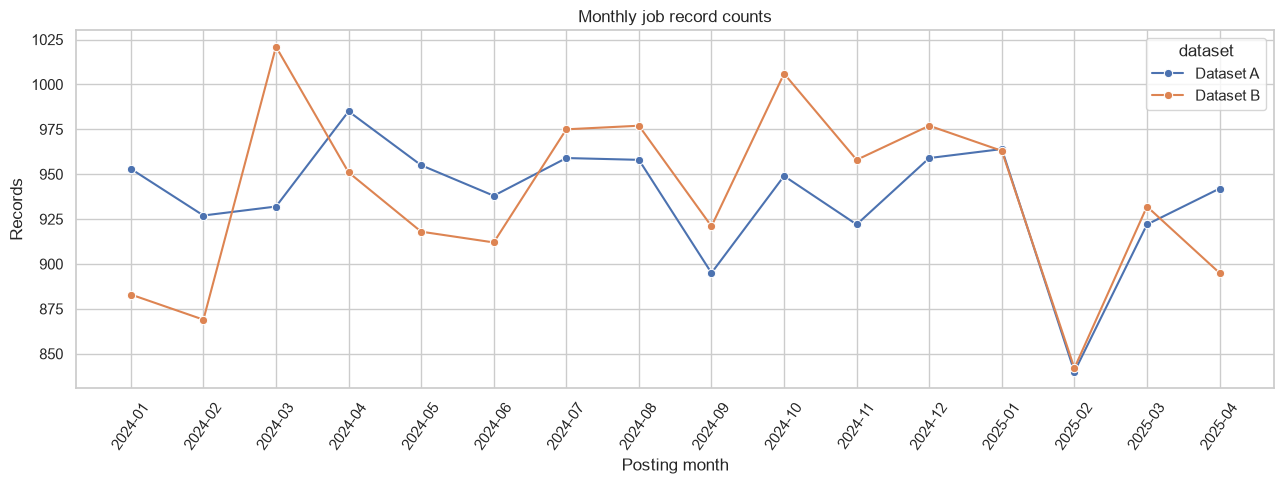

In [13]:
monthly = plot_df.groupby(["dataset", "posting_month"]).size().rename("postings").reset_index()
fig, ax = plt.subplots(figsize=(13, 5))
sns.lineplot(data=monthly, x="posting_month", y="postings", hue="dataset", marker="o", ax=ax)
ax.tick_params(axis="x", rotation=55)
ax.set(title="Monthly job record counts", xlabel="Posting month", ylabel="Records")
plt.tight_layout(); plt.show()

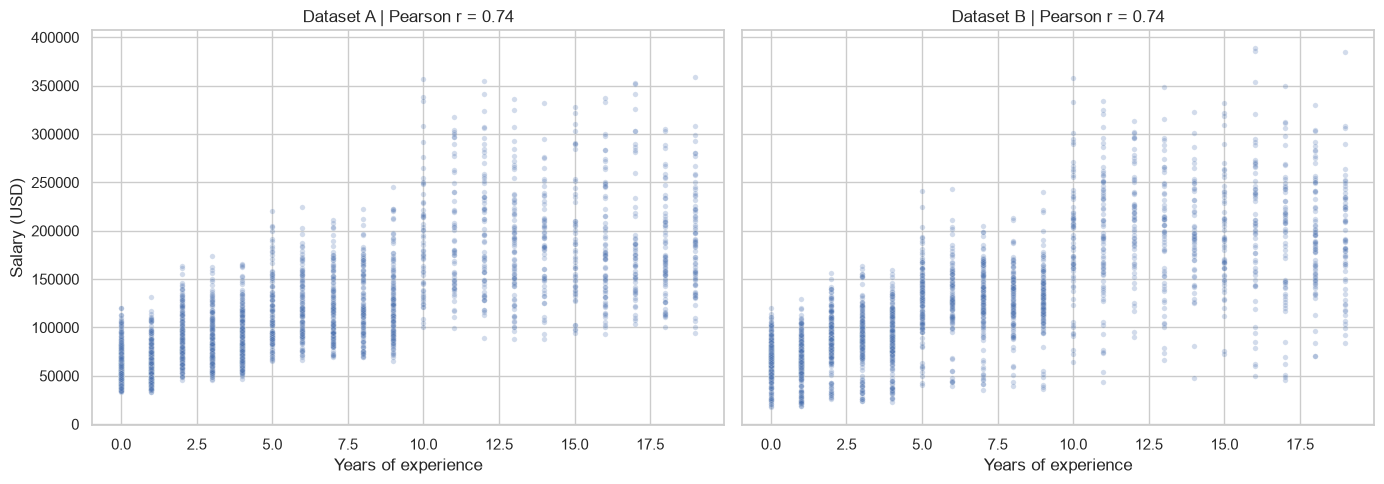

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (name, df) in zip(axes, clean.items()):
    sampled = df.sample(n=min(2500, len(df)), random_state=42)
    sns.scatterplot(data=sampled, x="years_experience", y="salary_usd", alpha=.25, s=15, ax=ax)
    r = df[["years_experience", "salary_usd"]].corr().iloc[0,1]
    ax.set(title=f"{name} | Pearson r = {r:.2f}", xlabel="Years of experience", ylabel="Salary (USD)")
plt.tight_layout(); plt.show()

In [15]:
for name, df in clean.items():
    med = df.groupby("experience_label").salary_usd.median()
    print(f"\n{name} — median salary by level:")
    display(med.reindex(order).round(0).to_frame("median_usd"))
    if "Entry" in med and "Executive" in med:
        print(f"Executive / entry median ratio: {med['Executive']/med['Entry']:.2f}×")
    stratified = df.pivot_table(index="experience_label", columns="remote_type", values="salary_usd", aggfunc="median")
    display(stratified.reindex(order).round(0))


Dataset A — median salary by level:


,median_usd
experience_label,
Entry,60374.0
Mid,84641.0
Senior,116907.0
Executive,177512.0


Executive / entry median ratio: 2.94×


remote_type,Hybrid,Onsite,Remote
experience_label,,,
Entry,60728.0,59644.0,61289.0
Mid,84035.0,84133.0,86514.0
Senior,118576.0,115769.0,116457.0
Executive,177931.0,177268.0,176592.0



Dataset B — median salary by level:


,median_usd
experience_label,
Entry,66462.0
Mid,91597.0
Senior,128543.0
Executive,197354.0


Executive / entry median ratio: 2.97×


remote_type,Hybrid,Onsite,Remote
experience_label,,,
Entry,65598.0,67056.0,66664.0
Mid,91179.0,92328.0,91347.0
Senior,128543.0,127704.0,128996.0
Executive,198002.0,196565.0,197302.0


In [16]:
def executive_summary(name, df):
    median = df.salary_usd.median()
    mean = df.salary_usd.mean()
    top_role = df.groupby("job_title").salary_usd.agg(["median", "size"])
    top_role = top_role[top_role["size"] >= 50].sort_values("median", ascending=False)
    role = top_role.index[0] if not top_role.empty else "N/A"
    role_salary = top_role.iloc[0]["median"] if not top_role.empty else float("nan")
    med_level = df.groupby("experience_label").salary_usd.median()
    top_skill = skill_counts[name].index[0]
    top_skill_n = int(skill_counts[name].iloc[0])
    top_country = df.company_location.value_counts().index[0]
    top_country_n = int(df.company_location.value_counts().iloc[0])
    remote_medians = df.groupby("remote_type").salary_usd.median()
    peak_month = df.posting_month.value_counts().idxmax()
    print(f"\n{name.upper()} — EXECUTIVE SUMMARY")
    print(f"1. Sample size: {len(df):,} records, posted {df.posting_date.min():%Y-%m-%d} to {df.posting_date.max():%Y-%m-%d}.")
    print(f"2. Median salary: ${median:,.0f}; mean salary: ${mean:,.0f}. Mean–median gap: ${mean-median:,.0f}.")
    print(f"3. Highest-median role (minimum 50 records): {role}, ${role_salary:,.0f}.")
    if {'Executive','Entry'}.issubset(med_level.index):
        print(f"4. Executive median: ${med_level['Executive']:,.0f}; entry median: ${med_level['Entry']:,.0f}; ratio {med_level['Executive']/med_level['Entry']:.2f}×.")
    print(f"5. Remote/hybrid/onsite medians: " + ", ".join(f"{k} ${v:,.0f}" for k,v in remote_medians.items()) + ".")
    print(f"6. Most mentioned skill: {top_skill} ({top_skill_n:,} records).")
    print(f"7. Most represented company location: {top_country} ({top_country_n:,} records).")
    print(f"8. Most represented posting month: {peak_month} ({df.posting_month.eq(peak_month).sum():,} records).")

for name, df in clean.items():
    executive_summary(name, df)
print("\nCROSS-DATASET COMPARISON")
med_a, med_b = [clean[n].salary_usd.median() for n in ["Dataset A", "Dataset B"]]
print(f"Dataset B median minus Dataset A median: ${med_b-med_a:,.0f} ({(med_b/med_a-1)*100:+.1f}%).")
print("Interpretation: a difference between two samples; not evidence of salary growth over time.")


DATASET A — EXECUTIVE SUMMARY
1. Sample size: 15,000 records, posted 2024-01-01 to 2025-04-30.
2. Median salary: $99,705; mean salary: $115,349. Mean–median gap: $15,644.
3. Highest-median role (minimum 50 records): Data Engineer, $104,447.
4. Executive median: $177,512; entry median: $60,374; ratio 2.94×.
5. Remote/hybrid/onsite medians: Hybrid $99,295, Onsite $98,817, Remote $100,614.
6. Most mentioned skill: Python (4,450 records).
7. Most represented company location: Germany (814 records).
8. Most represented posting month: 2024-04 (985 records).

DATASET B — EXECUTIVE SUMMARY
1. Sample size: 15,000 records, posted 2024-01-01 to 2025-04-30.
2. Median salary: $107,262; mean salary: $121,992. Mean–median gap: $14,730.
3. Highest-median role (minimum 50 records): Data Engineer, $112,505.
4. Executive median: $197,354; entry median: $66,462; ratio 2.97×.
5. Remote/hybrid/onsite medians: Hybrid $108,528, Onsite $106,506, Remote $107,070.
6. Most mentioned skill: Python (4,499 records)